# Artigo Medium: as passagens aéreas estão mais caras?

Notebook que gera **todos os números, tabelas e gráficos** do artigo publicado no Medium, com rótulos
em português. A análise completa (e a documentação dos métodos) está em `airline_prices.ipynb`;
aqui só se reproduz o que entra no texto.

- Lê `metrics_files/fare_metrics_by_year_deflated.csv`, gerado por `FilesProcessor` — não reprocessa
  os CSVs da ANAC.
- Todos os preços reais estão no poder de compra do **último mês da base** (a base de deflação do
  `deflate_metrics`), e esse rótulo é usado em todos os gráficos.
- As figuras são salvas em `figuras_artigo/` para subir no Medium.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

metrics = pd.read_csv("metrics_files/fare_metrics_by_year_deflated.csv")
metrics['Year'] = metrics['YearMonth'].str[:4].astype(int)

# base de deflação = mês mais recente da base completa (não do recorte filtrado)
BASE = pd.to_datetime(metrics['YearMonth'].max())
MESES = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez']
BASE_LABEL = f"R$ de {MESES[BASE.month - 1]}/{BASE.year}"
YLABEL_REAL = f"Tarifa média real ({BASE_LABEL})"

FIG_DIR = "figuras_artigo"
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'axes.spines.top': False,
                     'axes.spines.right': False})

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), bbox_inches='tight')

def weighted_average(values, weights):
    return (values * weights).sum() / weights.sum()

def seats_weighted(data, by):
    """Tarifa real (e nominal) média ponderada por assentos, agrupada por `by`."""
    return data.groupby(by).apply(lambda x: pd.Series({
        'AvgFareNominal': weighted_average(x['WeightedAverageFare'], x['TotalSeats']),
        'AvgFareReal': weighted_average(x['WeightedAverageFareReal'], x['TotalSeats']),
        'RoutesReporting': x['RouteAgg'].nunique(),
    }), include_groups=False).reset_index()

def br(x, fmt='+.2f'):
    """Número no formato brasileiro (vírgula decimal, ponto de milhar)."""
    return format(x, fmt.replace('.', ',.')).replace(',', '_').replace('.', ',').replace('_', '.')

def fmt_p(p, name='p'):
    return f"{name} = {br(p, '.3f')}" if p >= 0.001 else f"{name} < 0,001"

def trend_test(data, ycol, label, xcol='Year'):
    """Inclinação por MQO (R$/ano) e p-valor."""
    r = stats.linregress(data[xcol], data[ycol])
    sig = 'significativa' if r.pvalue < 0.05 else 'não significativa'
    print(f"{label}: {br(r.slope)} R$/ano, {fmt_p(r.pvalue)} ({sig} a 5%)")
    return r

yearly_all = metrics[metrics['Year'] < 2026]   # 2026 é ano parcial
yearly = seats_weighted(yearly_all, 'Year')

## 1. A quebra de 2010: rotas monitoradas antes e depois da Res. ANAC nº 140/2010

In [2]:
antes = yearly.loc[yearly['Year'] < 2010, 'RoutesReporting'].mean()
depois = yearly.loc[yearly['Year'] >= 2010, 'RoutesReporting'].mean()
print(f"Rotas reportando por ano, média 2002-2009: {antes:.0f}")
print(f"Rotas reportando por ano, média 2010-2025: {br(depois, '.0f')}")

Rotas reportando por ano, média 2002-2009: 66
Rotas reportando por ano, média 2010-2025: 4.524


## 2. Gráfico 1 — tarifa média nacional, nominal vs. real

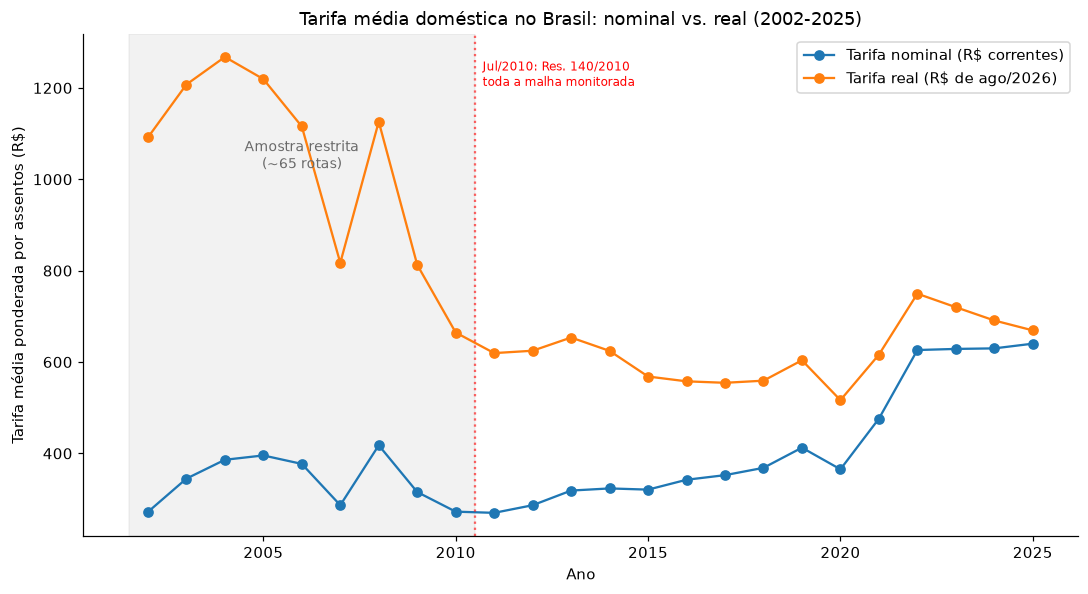

In [3]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(yearly['Year'], yearly['AvgFareNominal'], marker='o', label='Tarifa nominal (R$ correntes)')
ax.plot(yearly['Year'], yearly['AvgFareReal'], marker='o', label=f'Tarifa real ({BASE_LABEL})')
ax.axvspan(2001.5, 2010.5, color='grey', alpha=0.1)
ax.text(2006, yearly['AvgFareNominal'].max() * 1.6, 'Amostra restrita\n(~65 rotas)',
        ha='center', fontsize=9, color='dimgrey')
ax.axvline(2010.5, color='red', linestyle=':', alpha=0.6)
ax.text(2010.7, yearly['AvgFareReal'].max() * 0.95, 'Jul/2010: Res. 140/2010\ntoda a malha monitorada',
        fontsize=8, color='red')
ax.set_xlabel('Ano')
ax.set_ylabel('Tarifa média ponderada por assentos (R$)')
ax.set_title('Tarifa média doméstica no Brasil: nominal vs. real (2002-2025)')
ax.legend()
fig.tight_layout()
save(fig, '1_nacional_nominal_vs_real.png')
plt.show()

## 3. Resposta principal: há tendência no preço real nacional?

H0: não há tendência (inclinação = 0). O período confiável é **2011-2025** (anos completos sob a
mesma metodologia).

In [4]:
trend_test(yearly, 'AvgFareNominal', 'Nominal, 2002-2025')
trend_test(yearly, 'AvgFareReal', 'Real, 2002-2025')
trend_test(yearly[yearly['Year'] >= 2011], 'AvgFareReal', 'Real, 2011-2025');

Nominal, 2002-2025: +11,72 R$/ano, p < 0,001 (significativa a 5%)
Real, 2002-2025: -25,94 R$/ano, p < 0,001 (significativa a 5%)
Real, 2011-2025: +6,03 R$/ano, p = 0,130 (não significativa a 5%)


## 4. Gráfico 2 — todas as rotas vs. cesta fixa (mesmas rotas em todos os anos)

Rotas presentes em todos os anos 2002-2025: 44
Cesta fixa de 44 rotas, 2002-2025: -33,69 R$/ano, p < 0,001 (significativa a 5%)
Cesta fixa 2004->2010: R$ 1233 -> R$ 600 (-51%)
Cesta fixa 2011->2016: R$ 541 -> R$ 433 (-20%)
Cesta fixa 2016->2025: R$ 433 -> R$ 505 (+17%)


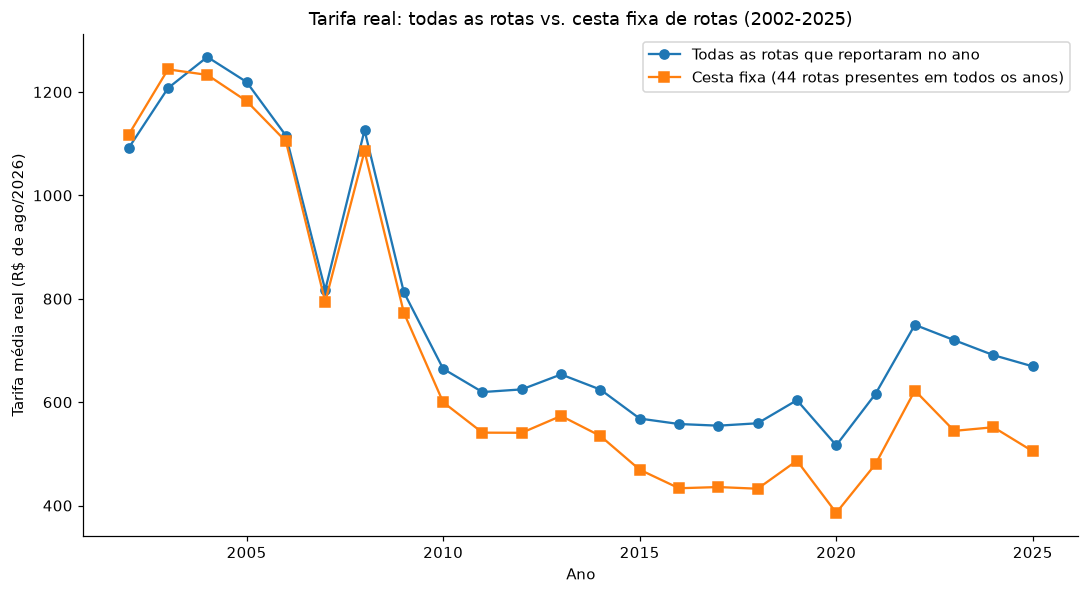

In [5]:
years_per_route = yearly_all.groupby('RouteAgg')['Year'].nunique()
basket_full = years_per_route[years_per_route == yearly_all['Year'].nunique()].index
fixed_full = seats_weighted(yearly_all[yearly_all['RouteAgg'].isin(basket_full)], 'Year')
print(f"Rotas presentes em todos os anos 2002-2025: {len(basket_full)}")
trend_test(fixed_full, 'AvgFareReal', f'Cesta fixa de {len(basket_full)} rotas, 2002-2025')

# onde está a queda? variação da cesta fixa por subperíodo
fb = fixed_full.set_index('Year')['AvgFareReal']
for a, b in [(2004, 2010), (2011, 2016), (2016, 2025)]:
    print(f"Cesta fixa {a}->{b}: R$ {fb[a]:.0f} -> R$ {fb[b]:.0f} ({fb[b] / fb[a] - 1:+.0%})")

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(yearly['Year'], yearly['AvgFareReal'], marker='o', label='Todas as rotas que reportaram no ano')
ax.plot(fixed_full['Year'], fixed_full['AvgFareReal'], marker='s',
        label=f'Cesta fixa ({len(basket_full)} rotas presentes em todos os anos)')
ax.set_xlabel('Ano')
ax.set_ylabel(YLABEL_REAL)
ax.set_title('Tarifa real: todas as rotas vs. cesta fixa de rotas (2002-2025)')
ax.legend()
fig.tight_layout()
save(fig, '2_cesta_fixa.png')
plt.show()

## 5. Tabela — as 5 rotas mais movimentadas (2002-2025)

In [6]:
route_seats = yearly_all.groupby('RouteAgg')['TotalSeats'].sum().sort_values(ascending=False)
share = route_seats / route_seats.sum() * 100
top5_routes = route_seats.head(5).index.tolist()
years_available = yearly_all.groupby('RouteAgg')['Year'].nunique()
tab = pd.DataFrame({'Participação (%)': share.head(5).round(2),
                    'Anos com dados': years_available[top5_routes]})
print(f"Participação conjunta: {br(share.head(5).sum(), '.1f')}% dos assentos vendidos")
tab

Participação conjunta: 13,7% dos assentos vendidos


,Participação (%),Anos com dados
RouteAgg,,
CGH >> SDU,5.71,24
BSB >> CGH,2.25,24
GRU >> SSA,2.14,24
CGH >> POA,1.87,24
GRU >> REC,1.75,22


## 6. Gráfico 3 — tarifa real das 5 rotas mais movimentadas, e tendência por rota

CGH >> SDU, 2011-2025: -14,27 R$/ano, p = 0,050 (não significativa a 5%)
BSB >> CGH, 2011-2025: -16,73 R$/ano, p = 0,003 (significativa a 5%)


GRU >> SSA, 2011-2025: +5,75 R$/ano, p = 0,269 (não significativa a 5%)
CGH >> POA, 2011-2025: -3,44 R$/ano, p = 0,499 (não significativa a 5%)
GRU >> REC, 2011-2025: -8,90 R$/ano, p = 0,155 (não significativa a 5%)


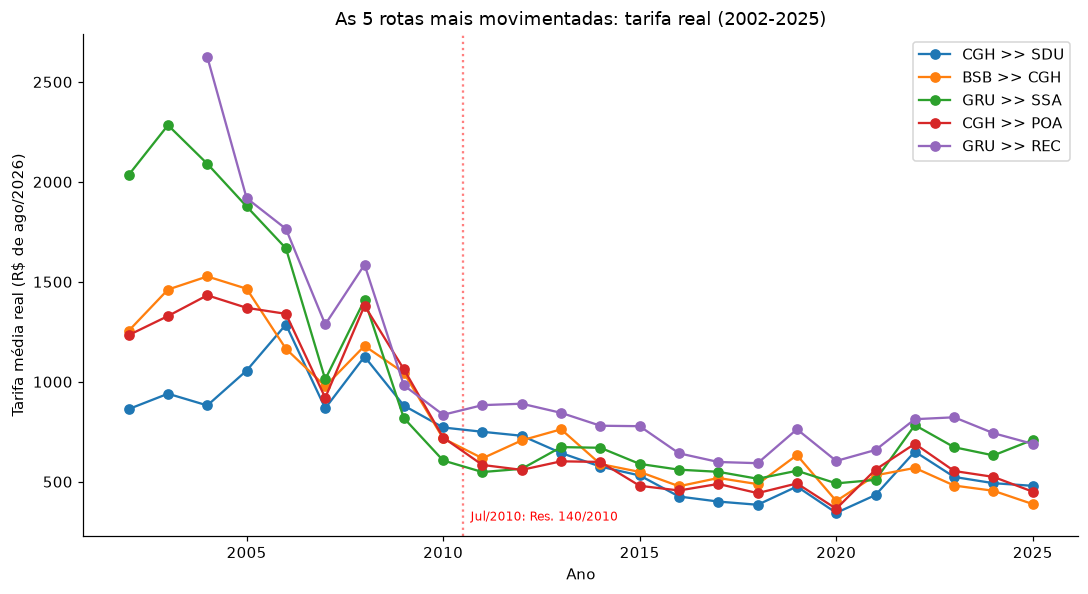

In [7]:
top5_yearly = {}
for route in top5_routes:
    route_yearly = seats_weighted(yearly_all[yearly_all['RouteAgg'] == route], 'Year')
    top5_yearly[route] = route_yearly
    trend_test(route_yearly[route_yearly['Year'] >= 2011], 'AvgFareReal', f'{route}, 2011-2025')

fig, ax = plt.subplots(figsize=(10, 5.5))
for route in top5_routes:
    ax.plot(top5_yearly[route]['Year'], top5_yearly[route]['AvgFareReal'], marker='o', label=route)
ax.axvline(2010.5, color='red', linestyle=':', alpha=0.5)
ax.text(2010.7, ax.get_ylim()[0] + 0.03 * (ax.get_ylim()[1] - ax.get_ylim()[0]),
        'Jul/2010: Res. 140/2010', fontsize=8, color='red')
ax.set_xlabel('Ano')
ax.set_ylabel(YLABEL_REAL)
ax.set_title('As 5 rotas mais movimentadas: tarifa real (2002-2025)')
ax.legend()
fig.tight_layout()
save(fig, '3_top5_por_rota.png')
plt.show()

## 7. Gráfico 4 — top 5 combinado vs. demais rotas combinadas (anual)

Top 5, 2002-2025: -37,46 R$/ano, p < 0,001 (significativa a 5%)
Top 5, 2011-2025: -9,87 R$/ano, p = 0,058 (não significativa a 5%)
Demais rotas, 2002-2025: -23,36 R$/ano, p < 0,001 (significativa a 5%)
Demais rotas, 2011-2025: +7,82 R$/ano, p = 0,050 (não significativa a 5%)


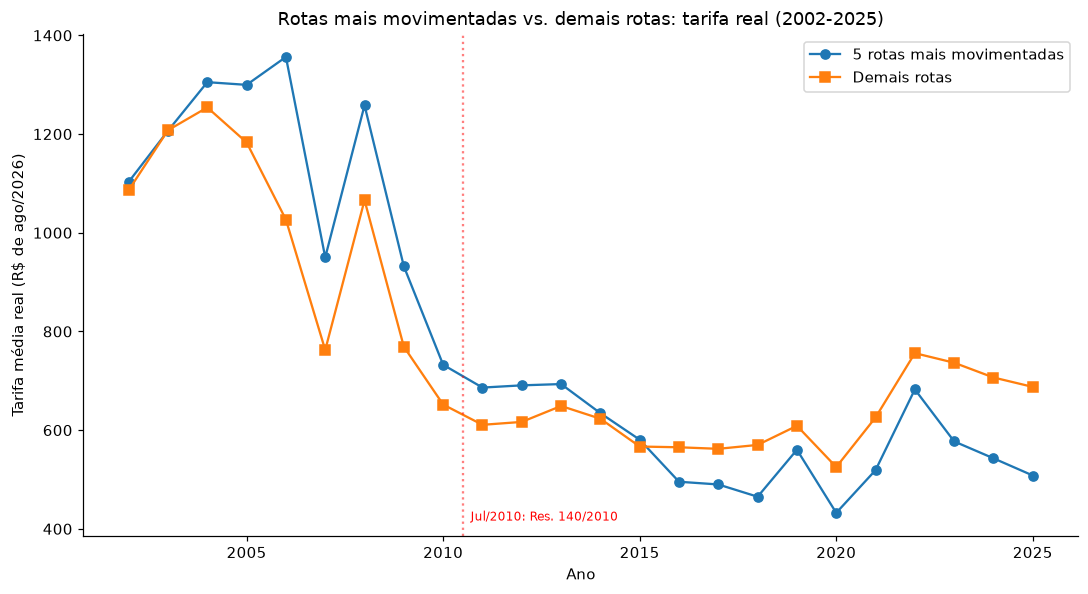

In [8]:
is_top5 = yearly_all['RouteAgg'].isin(top5_routes)
top5_combined = seats_weighted(yearly_all[is_top5], 'Year')
others_combined = seats_weighted(yearly_all[~is_top5], 'Year')
for name, d in [('Top 5', top5_combined), ('Demais rotas', others_combined)]:
    trend_test(d, 'AvgFareReal', f'{name}, 2002-2025')
    trend_test(d[d['Year'] >= 2011], 'AvgFareReal', f'{name}, 2011-2025')

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(top5_combined['Year'], top5_combined['AvgFareReal'], marker='o', label='5 rotas mais movimentadas')
ax.plot(others_combined['Year'], others_combined['AvgFareReal'], marker='s', label='Demais rotas')
ax.axvline(2010.5, color='red', linestyle=':', alpha=0.5)
ax.text(2010.7, ax.get_ylim()[0] + 0.03 * (ax.get_ylim()[1] - ax.get_ylim()[0]),
        'Jul/2010: Res. 140/2010', fontsize=8, color='red')
ax.set_xlabel('Ano')
ax.set_ylabel(YLABEL_REAL)
ax.set_title('Rotas mais movimentadas vs. demais rotas: tarifa real (2002-2025)')
ax.legend()
fig.tight_layout()
save(fig, '4_top5_vs_demais_anual.png')
plt.show()

## 8. Janela mensal jan/2016 - ago/2026

Mesmo método de `airline_prices.ipynb`: série dessazonalizada (média de cada mês do calendário
removida) e p-valor ajustado para autocorrelação de 1ª ordem (tamanho amostral efetivo
n·(1-ρ)/(1+ρ)).

A **diferença** é apresentada como *demais − top 5* (positiva = quanto a mais se paga, em média,
fora das 5 grandes rotas), que é a leitura usada no texto.

In [9]:
WINDOW_START, WINDOW_END = '2016-01', metrics['YearMonth'].max()
monthly = metrics[(metrics['YearMonth'] >= WINDOW_START) & (metrics['YearMonth'] <= WINDOW_END)]

route_seats_w = monthly.groupby('RouteAgg')['TotalSeats'].sum().sort_values(ascending=False)
share_w = route_seats_w / route_seats_w.sum() * 100
top5_window = route_seats_w.head(5).index.tolist()
print(f"Entra no top 5: {sorted(set(top5_window) - set(top5_routes))}; sai: {sorted(set(top5_routes) - set(top5_window))}")
print(f"Participação conjunta do top 5 na janela: {br(share_w.head(5).sum(), '.2f')}%")
share_w.head(5).round(2).rename('Participação (%)').to_frame()

Entra no top 5: ['CGH >> CNF']; sai: ['GRU >> SSA']
Participação conjunta do top 5 na janela: 10,18%


,Participação (%)
RouteAgg,
CGH >> SDU,3.68
BSB >> CGH,1.76
GRU >> REC,1.65
CGH >> CNF,1.59
CGH >> POA,1.50


In [10]:
def monthly_index(data):
    idx = data.groupby('YearMonth').apply(
        lambda x: weighted_average(x['WeightedAverageFareReal'], x['TotalSeats']), include_groups=False
    ).rename('AvgFareReal').reset_index()
    date = pd.to_datetime(idx['YearMonth'])
    idx['Date'] = date
    idx['Time'] = date.dt.year + (date.dt.month - 1) / 12
    month_effect = idx.groupby(date.dt.month)['AvgFareReal'].transform('mean')
    idx['AvgFareRealDeseasonalized'] = idx['AvgFareReal'] - month_effect + idx['AvgFareReal'].mean()
    return idx

def monthly_trend_test(data, ycol, label):
    r = stats.linregress(data['Time'], data[ycol])
    resid = data[ycol] - (r.intercept + r.slope * data['Time'])
    rho = resid.autocorr(1)
    n = len(data)
    n_eff = n * (1 - rho) / (1 + rho)
    p_adj = 2 * stats.t.sf(abs(r.slope / (r.stderr * np.sqrt((n - 2) / (n_eff - 2)))), n_eff - 2)
    sig = 'significativa' if p_adj < 0.05 else 'não significativa'
    print(f"{label}: {br(r.slope)} R$/ano, {fmt_p(p_adj, 'p ajustado')} ({sig} a 5%)")
    return r

is_top5_w = monthly['RouteAgg'].isin(top5_window)
top5_m = monthly_index(monthly[is_top5_w])
others_m = monthly_index(monthly[~is_top5_w])
print(f"Demais rotas = {(~is_top5_w * monthly['TotalSeats']).sum() / monthly['TotalSeats'].sum():.0%} dos assentos")

monthly_trend_test(top5_m, 'AvgFareRealDeseasonalized', 'Top 5, dessazonalizado')
monthly_trend_test(others_m, 'AvgFareRealDeseasonalized', 'Demais rotas, dessazonalizado')

diff_m = top5_m[['YearMonth', 'Date', 'Time']].copy()
diff_m['Diff'] = others_m['AvgFareRealDeseasonalized'] - top5_m['AvgFareRealDeseasonalized']
diff_fit = monthly_trend_test(diff_m, 'Diff', 'Diferença (demais − top 5), dessazonalizada')

# a diferença média por ano, para o "de ~R$ 100 para ~R$ 200" do texto
diff_m.groupby(diff_m['YearMonth'].str[:4])['Diff'].mean().round(0).rename('Diferença média (R$)').to_frame().T

Demais rotas = 90% dos assentos
Top 5, dessazonalizado: +8,74 R$/ano, p ajustado = 0,195 (não significativa a 5%)
Demais rotas, dessazonalizado: +20,49 R$/ano, p ajustado = 0,003 (significativa a 5%)
Diferença (demais − top 5), dessazonalizada: +11,74 R$/ano, p ajustado < 0,001 (significativa a 5%)


YearMonth,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Diferença média (R$),101.0,107.0,129.0,79.0,128.0,144.0,126.0,182.0,204.0,222.0,169.0


## 9. Gráfico 5 — mensal 2016-2026 e a diferença entre os grupos

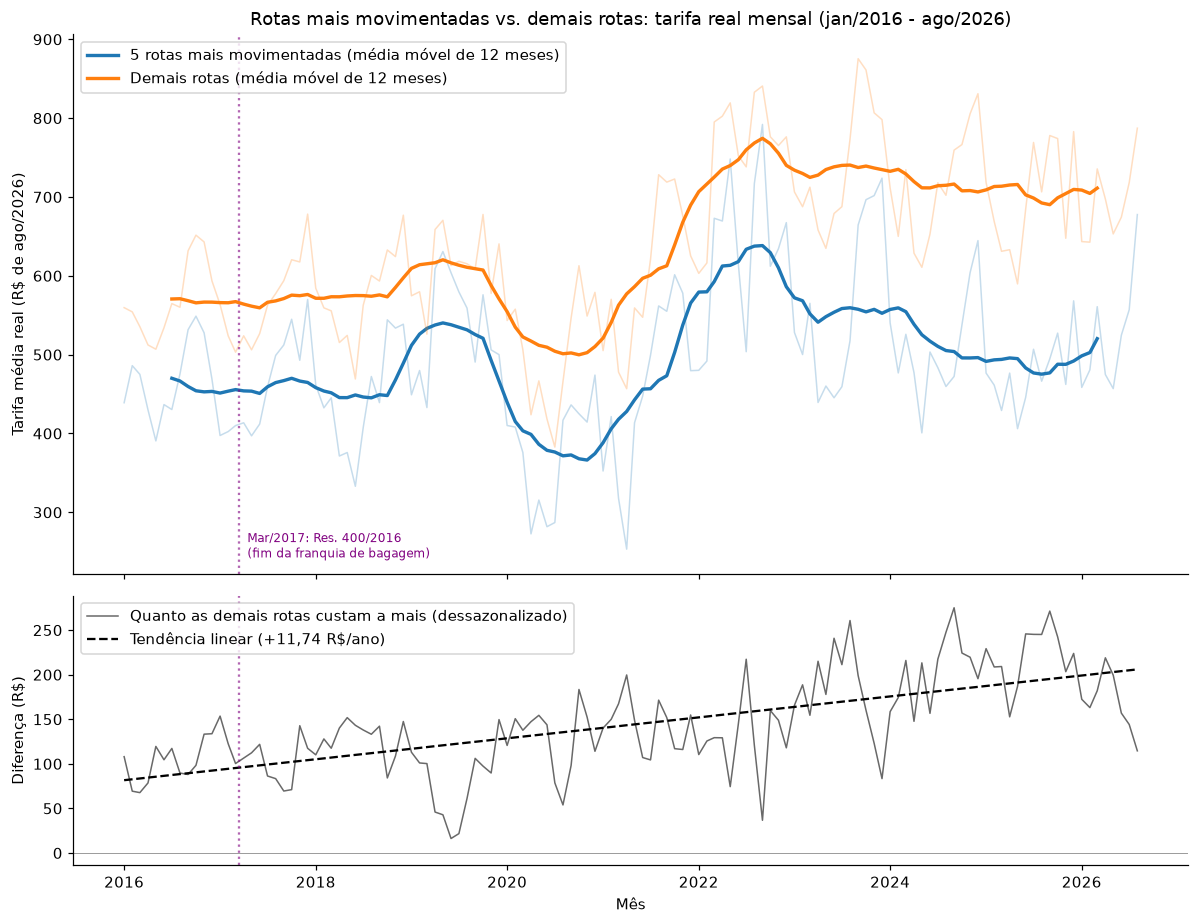

In [11]:
fig, (ax, ax_d) = plt.subplots(2, 1, figsize=(11, 8.5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
for idx, label, color in [(top5_m, '5 rotas mais movimentadas', 'tab:blue'),
                          (others_m, 'Demais rotas', 'tab:orange')]:
    ax.plot(idx['Date'], idx['AvgFareReal'], color=color, alpha=0.25, linewidth=1)
    ax.plot(idx['Date'], idx['AvgFareReal'].rolling(12, center=True).mean(), color=color, linewidth=2.2,
            label=f'{label} (média móvel de 12 meses)')
ax.set_ylabel(YLABEL_REAL)
ax.set_title(f'Rotas mais movimentadas vs. demais rotas: tarifa real mensal ({MESES[0]}/2016 - {MESES[BASE.month - 1]}/{BASE.year})')
ax.legend(loc='upper left')

ax_d.plot(diff_m['Date'], diff_m['Diff'], color='dimgrey', linewidth=1,
          label='Quanto as demais rotas custam a mais (dessazonalizado)')
ax_d.plot(diff_m['Date'], diff_fit.intercept + diff_fit.slope * diff_m['Time'], color='black', linestyle='--',
          label=f'Tendência linear ({br(diff_fit.slope)} R$/ano)')
ax_d.axhline(0, color='grey', linewidth=0.5)
ax_d.set_ylabel('Diferença (R$)')
ax_d.set_xlabel('Mês')
ax_d.legend(loc='upper left')

for a in (ax, ax_d):
    a.axvline(pd.Timestamp('2017-03-15'), color='purple', linestyle=':', alpha=0.6)
ax.text(pd.Timestamp('2017-04-15'), ax.get_ylim()[0] + 0.03 * (ax.get_ylim()[1] - ax.get_ylim()[0]),
        'Mar/2017: Res. 400/2016\n(fim da franquia de bagagem)', fontsize=8, color='purple')
fig.tight_layout()
save(fig, '5_mensal_2016_2026.png')
plt.show()

## 10. Assentos vendidos por ano (apoio à discussão sobre acesso)

In [12]:
seats = yearly_all.assign(Grupo=np.where(yearly_all['RouteAgg'].isin(top5_window), 'Top 5', 'Demais rotas'))
(seats[seats['Year'] >= 2015].pivot_table(index='Year', columns='Grupo', values='TotalSeats', aggfunc='sum')
 / 1e6).round(1).rename_axis(columns='Assentos (milhões)')

Assentos (milhões),Demais rotas,Top 5
Year,,
2015,44.3,4.9
2016,36.4,4.2
2017,35.6,4.2
2018,34.6,3.9
2019,34.6,3.9
2020,19.8,1.9
2021,24.4,2.3
2022,23.1,2.4
2023,24.4,3.0
